# Stage 1: Data Quality — Dexcom Glucose (Participant 001)

Before analysing trends, we check whether the glucose data is complete and trustworthy.

| # | Question |
|---|---|
| Q1 | What are the first and last timestamps? How many days of data? |
| Q2 | How many readings exist vs. expected (one per 5 min)? What % is missing? |
| Q3 | Where are the gaps, and how long is each one? |
| Q4 | Are there any non-numeric values (e.g. "Low" / "High")? |
| Q5 | Does the first day look unusual (sensor warm-up)? |
| Q6 | Are there any physically implausible jumps between consecutive readings? |

## Setup

Imports, file path, and a few settings used throughout the notebook.

- `INTERVAL` is the Dexcom sampling interval (5 min).
- `GAP_THRESHOLD` defines a gap: any spacing longer than 7.5 min means at least one reading was missed. (Dexcom timestamps drift by a few seconds, so we don't use exactly 5 min.)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PATH = "../../../datasets/big-ideas-glycemic-wearable/001/Dexcom_001.csv"

TS_COL = "Timestamp (YYYY-MM-DDThh:mm:ss)"
GLU_COL = "Glucose Value (mg/dL)"

INTERVAL = pd.Timedelta("5min")
GAP_THRESHOLD = pd.Timedelta("7.5min")

pd.set_option("display.max_rows", 100)

## Load the raw data

We skip the 12 metadata rows and read the glucose column **as text**. Reading it as text keeps any non-numeric entries (like `"Low"` or `"High"`) visible so we can find them in Q4, instead of pandas silently hiding them.

In [6]:
raw = pd.read_csv(PATH, skiprows=range(1, 13), dtype={GLU_COL: str})
raw[TS_COL] = pd.to_datetime(raw[TS_COL])

print("Rows:", len(raw))
raw.head()

Rows: 2561


,Index,Timestamp (YYYY-MM-DDThh:mm:ss),Event Type,Event Subtype,Patient Info,Device Info,Source Device ID,Glucose Value (mg/dL),Insulin Value (u),Carb Value (grams),Duration (hh:mm:ss),Glucose Rate of Change (mg/dL/min),Transmitter Time (Long Integer)
0,13,2020-02-13 17:23:32,EGV,NaN,NaN,NaN,iPhone G6,61.0,NaN,NaN,NaN,NaN,11101.0
1,14,2020-02-13 17:28:32,EGV,NaN,NaN,NaN,iPhone G6,59.0,NaN,NaN,NaN,NaN,11401.0
2,15,2020-02-13 17:33:32,EGV,NaN,NaN,NaN,iPhone G6,58.0,NaN,NaN,NaN,NaN,11701.0
3,16,2020-02-13 17:38:32,EGV,NaN,NaN,NaN,iPhone G6,59.0,NaN,NaN,NaN,NaN,12001.0
4,17,2020-02-13 17:43:31,EGV,NaN,NaN,NaN,iPhone G6,63.0,NaN,NaN,NaN,NaN,12301.0


### Which event types are in the file?

Glucose readings are labelled `EGV` (Estimated Glucose Value). Other types, such as calibrations, would appear here too. We keep only `EGV` rows for the quality checks.

In [7]:
print(raw["Event Type"].value_counts(dropna=False))

egv = raw[raw["Event Type"] == "EGV"].sort_values(TS_COL).reset_index(drop=True)
print("\nEGV rows:", len(egv))

Event Type
EGV    2561
Name: count, dtype: int64

EGV rows: 2561


### Duplicate timestamps

Two readings with the same timestamp would distort counts and differences later, so we check for them first.

In [8]:
dupes = egv[egv.duplicated(TS_COL, keep=False)]
print("Duplicate timestamps:", dupes[TS_COL].nunique())
dupes

Duplicate timestamps: 0


,Index,Timestamp (YYYY-MM-DDThh:mm:ss),Event Type,Event Subtype,Patient Info,Device Info,Source Device ID,Glucose Value (mg/dL),Insulin Value (u),Carb Value (grams),Duration (hh:mm:ss),Glucose Rate of Change (mg/dL/min),Transmitter Time (Long Integer)


In [29]:
# Keep the first reading for any duplicated timestamp
egv = egv.drop_duplicates(TS_COL, keep="first").reset_index(drop=True)
egv

,Index,Timestamp (YYYY-MM-DDThh:mm:ss),Event Type,Event Subtype,Patient Info,Device Info,Source Device ID,Glucose Value (mg/dL),Insulin Value (u),Carb Value (grams),Duration (hh:mm:ss),Glucose Rate of Change (mg/dL/min),Transmitter Time (Long Integer),delta,glucose,period,hour,rate
0,13,2020-02-13 17:23:32,EGV,NaN,NaN,NaN,iPhone G6,61.0,NaN,NaN,NaN,NaN,11101.0,NaT,61.0,First 24 h,17,NaN
1,14,2020-02-13 17:28:32,EGV,NaN,NaN,NaN,iPhone G6,59.0,NaN,NaN,NaN,NaN,11401.0,0 days 00:05:00,59.0,First 24 h,17,-0.400000
2,15,2020-02-13 17:33:32,EGV,NaN,NaN,NaN,iPhone G6,58.0,NaN,NaN,NaN,NaN,11701.0,0 days 00:05:00,58.0,First 24 h,17,-0.200000
3,16,2020-02-13 17:38:32,EGV,NaN,NaN,NaN,iPhone G6,59.0,NaN,NaN,NaN,NaN,12001.0,0 days 00:05:00,59.0,First 24 h,17,0.200000
4,17,2020-02-13 17:43:31,EGV,NaN,NaN,NaN,iPhone G6,63.0,NaN,NaN,NaN,NaN,12301.0,0 days 00:04:59,63.0,First 24 h,17,0.802676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2556,2569,2020-02-22 17:33:23,EGV,NaN,NaN,NaN,iPhone G6,139.0,NaN,NaN,NaN,NaN,789294.0,0 days 00:05:00,139.0,Rest,17,0.400000
2557,2570,2020-02-22 17:38:23,EGV,NaN,NaN,NaN,iPhone G6,141.0,NaN,NaN,NaN,NaN,789594.0,0 days 00:05:00,141.0,Rest,17,0.400000
2558,2571,2020-02-22 17:43:23,EGV,NaN,NaN,NaN,iPhone G6,143.0,NaN,NaN,NaN,NaN,789894.0,0 days 00:05:00,143.0,Rest,17,0.400000
2559,2572,2020-02-22 17:48:22,EGV,NaN,NaN,NaN,iPhone G6,139.0,NaN,NaN,NaN,NaN,790194.0,0 days 00:04:59,139.0,Rest,17,-0.802676


---
## Q1: First and last timestamps, number of days

We look at the overall recording window and how many readings fall on each calendar day. The first and last days are usually partial, because the sensor was inserted and removed partway through the day.

In [10]:
start, end = egv[TS_COL].min(), egv[TS_COL].max()
duration = end - start

print("First reading:", start)
print("Last reading: ", end)
print("Duration:     ", duration)
print(f"Days:          {duration / pd.Timedelta('1D'):.2f}")

First reading: 2020-02-13 17:23:32
Last reading:  2020-02-22 17:53:23
Duration:      9 days 00:29:51
Days:          9.02


In [11]:
# Readings per calendar day (a full day = 288 readings)
per_day = egv.groupby(egv[TS_COL].dt.date.rename("date")).size().rename("readings").to_frame()
per_day["% of full day"] = (per_day["readings"] / 288 * 100).round(1)
per_day

,readings,% of full day
date,,
2020-02-13,80,27.8
2020-02-14,288,100.0
2020-02-15,287,99.7
2020-02-16,288,100.0
2020-02-17,288,100.0
2020-02-18,288,100.0
2020-02-19,284,98.6
2020-02-20,255,88.5
2020-02-21,288,100.0


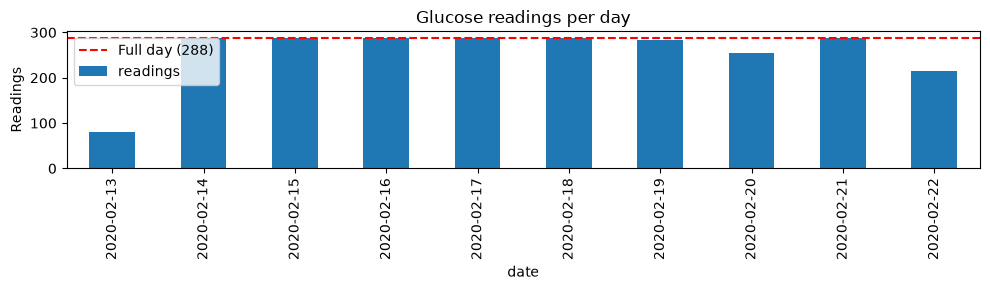

In [12]:
ax = per_day["readings"].plot(kind="bar", figsize=(10, 3), color="tab:blue")
ax.axhline(288, color="red", ls="--", label="Full day (288)")
ax.set_ylabel("Readings")
ax.set_title("Glucose readings per day")
ax.legend()
plt.tight_layout()
plt.show()

---
## Q2: Existing vs. expected readings, % missing

Expected readings = recording duration ÷ 5 min + 1. Comparing that with the actual count gives the overall completeness.

In [13]:
expected = int(duration / INTERVAL) + 1
actual = len(egv)
missing = expected - actual

print(f"Expected readings: {expected}")
print(f"Actual readings:   {actual}")
print(f"Missing readings:  {missing}")
print(f"Completeness:      {actual / expected * 100:.1f}%")
print(f"Missing:           {missing / expected * 100:.1f}%")

Expected readings: 2598
Actual readings:   2561
Missing readings:  37
Completeness:      98.6%
Missing:           1.4%


---
## Q3: Where are the gaps, and how long are they?

We compute the time between consecutive readings. Any spacing above `GAP_THRESHOLD` is a gap. For each gap we record when it started and ended, how long it lasted, and roughly how many readings were missed.

As a rough guide: gaps under 30 min are usually short signal dropouts (phone out of range), while a gap of about 2 hours can indicate a **sensor change**, because the Dexcom G6 needs a 2-hour warm-up before it reports again.

In [14]:
egv["delta"] = egv[TS_COL].diff()

print("Typical spacing between readings:")
print(egv["delta"].describe())

Typical spacing between readings:
count                      2560
mean     0 days 00:05:04.449609
std      0 days 00:03:39.441847
min             0 days 00:04:58
25%             0 days 00:05:00
50%             0 days 00:05:00
75%             0 days 00:05:00
max             0 days 03:09:59
Name: delta, dtype: object


In [15]:
gap_mask = egv["delta"] > GAP_THRESHOLD

gaps = pd.DataFrame({
    "gap_start": egv[TS_COL].shift(1)[gap_mask],
    "gap_end": egv[TS_COL][gap_mask],
    "duration": egv["delta"][gap_mask],
}).reset_index(drop=True)
gaps["missed_readings"] = (gaps["duration"] / INTERVAL).round().astype(int) - 1
gaps["duration_min"] = (gaps["duration"].dt.total_seconds() / 60).round(1)

print("Number of gaps:", len(gaps))
gaps

Number of gaps: 2


,gap_start,gap_end,duration,missed_readings,duration_min
0,2020-02-15 09:03:30,2020-02-15 09:13:30,0 days 00:10:00,1,10.0
1,2020-02-19 23:38:26,2020-02-20 02:48:25,0 days 03:09:59,37,190.0


In [16]:
# Group gaps by length to see what kind of gaps dominate
bins = [7.5, 15, 30, 60, 120, np.inf]
labels = ["7.5–15 min", "15–30 min", "30–60 min", "1–2 h", "> 2 h"]
gaps["category"] = pd.cut(gaps["duration_min"], bins=bins, labels=labels)

gaps.groupby("category", observed=False).agg(
    count=("duration_min", "size"),
    total_missed=("missed_readings", "sum"),
)

,count,total_missed
category,,
7.5–15 min,1,1
15–30 min,0,0
30–60 min,0,0
1–2 h,0,0
> 2 h,1,37


### Gap timeline

The full glucose trace with each gap shaded in red, so you can see where data is missing.

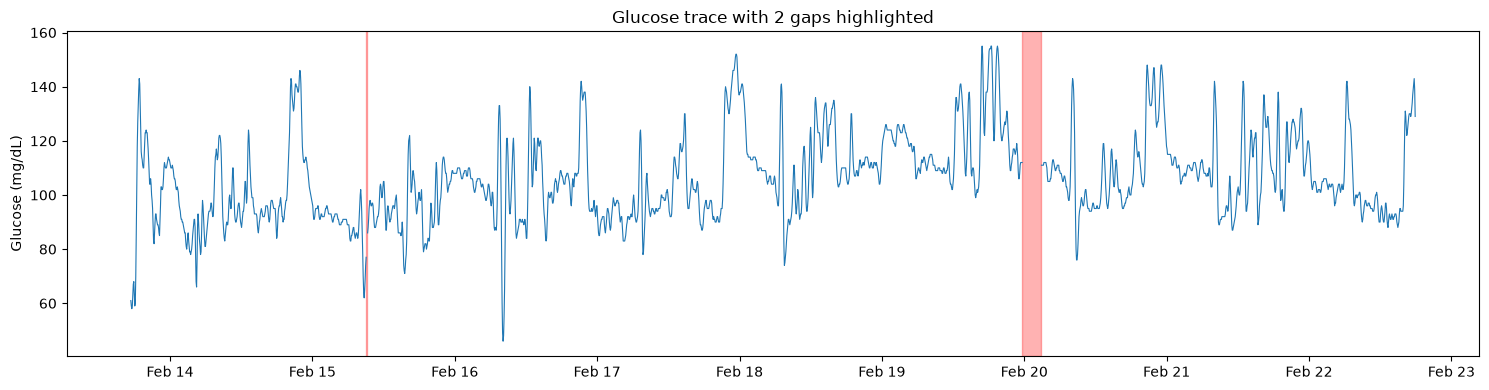

In [17]:
fig, ax = plt.subplots(figsize=(15, 4))

# Convert to numbers for plotting; matplotlib breaks the line at NaN values
plot_vals = pd.to_numeric(egv[GLU_COL], errors="coerce").copy()
plot_vals[gap_mask] = np.nan  # break the line at each gap

ax.plot(egv[TS_COL], plot_vals, lw=0.8, color="tab:blue")
for _, g in gaps.iterrows():
    ax.axvspan(g["gap_start"], g["gap_end"], color="red", alpha=0.3)

ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"Glucose trace with {len(gaps)} gaps highlighted")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

---
## Q4: Non-numeric values in the glucose column

Dexcom writes `"Low"` when glucose is below 40 mg/dL and `"High"` when it is above 400 mg/dL, since those are outside the sensor's measuring range. We try converting every value to a number and list anything that fails.

We also check that numeric values fall inside the G6's reporting range of 40–400 mg/dL.

In [18]:
egv["glucose"] = pd.to_numeric(egv[GLU_COL], errors="coerce")

non_numeric = egv[egv["glucose"].isna()]
print("Non-numeric or empty values:", len(non_numeric))
print(non_numeric[GLU_COL].value_counts(dropna=False))

Non-numeric or empty values: 0
Series([], Name: count, dtype: int64)


In [19]:
out_of_range = egv[(egv["glucose"] < 40) | (egv["glucose"] > 400)]
print("Numeric values outside 40–400 mg/dL:", len(out_of_range))

print("\nGlucose range in the data:")
egv["glucose"].describe()

Numeric values outside 40–400 mg/dL: 0

Glucose range in the data:


count    2561.000000
mean      106.093713
std        15.771012
min        46.000000
25%        95.000000
50%       105.000000
75%       114.000000
max       155.000000
Name: glucose, dtype: float64

---
## Q5: Does the first day look unusual?

CGM sensors are often less accurate in the first ~24 hours after insertion. We compare the first 24 h against the rest of the recording using summary statistics and plots.

If the first day shows noticeably lower values, a different spread, or erratic movement, you may want to exclude it from later analysis. Keep in mind that a difference could also be genuine (for example, a different diet that day), so look at the plot as well as the numbers.

In [20]:
first_24h_end = start + pd.Timedelta("24h")
egv["period"] = np.where(egv[TS_COL] < first_24h_end, "First 24 h", "Rest")

def summarize(s):
    return pd.Series({
        "readings": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "CV %": s.std() / s.mean() * 100,
        "min": s.min(),
        "max": s.max(),
        "% < 70": (s < 70).mean() * 100,
    })

egv.groupby("period")["glucose"].apply(summarize).unstack().round(1)

,readings,mean,median,std,CV %,min,max,% < 70
period,,,,,,,,
First 24 h,289.0,96.9,95.0,14.3,14.8,58.0,143.0,4.2
Rest,2272.0,107.3,106.0,15.6,14.5,46.0,155.0,0.4


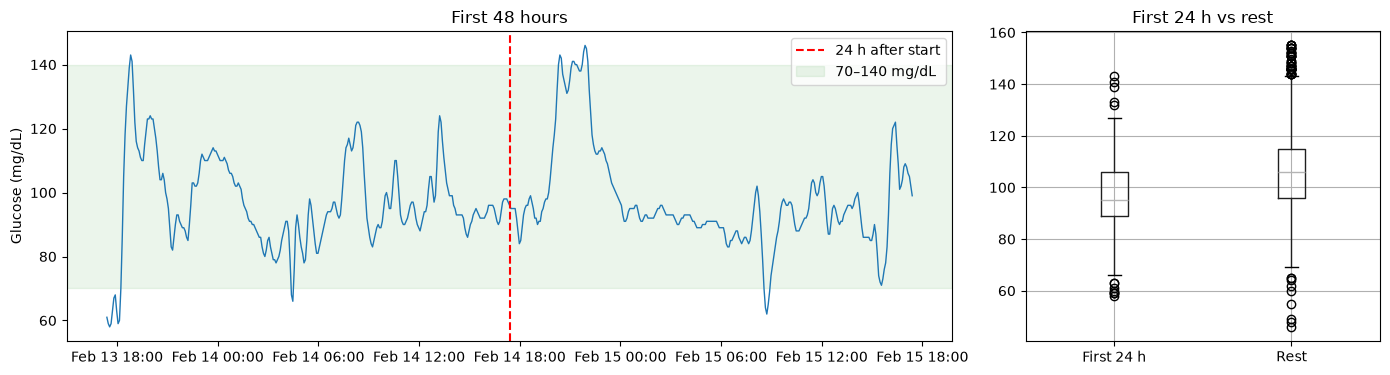

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.5, 1]})

# Left: first 48 h, with the 24 h boundary marked
first_48 = egv[egv[TS_COL] < start + pd.Timedelta("48h")]
axes[0].plot(first_48[TS_COL], first_48["glucose"], lw=1)
axes[0].axvline(first_24h_end, color="red", ls="--", label="24 h after start")
axes[0].axhspan(70, 140, color="green", alpha=0.08, label="70–140 mg/dL")
axes[0].set_ylabel("Glucose (mg/dL)")
axes[0].set_title("First 48 hours")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d %H:%M"))
axes[0].legend()

# Right: distribution comparison
egv.boxplot(column="glucose", by="period", ax=axes[1])
axes[1].set_title("First 24 h vs rest")
axes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Same time of day comparison

Comparing the first day with the average of the other days at the **same hours** removes the effect of daily routine. If the first day sits well below or above the other days' typical band, warm-up inaccuracy is more likely.

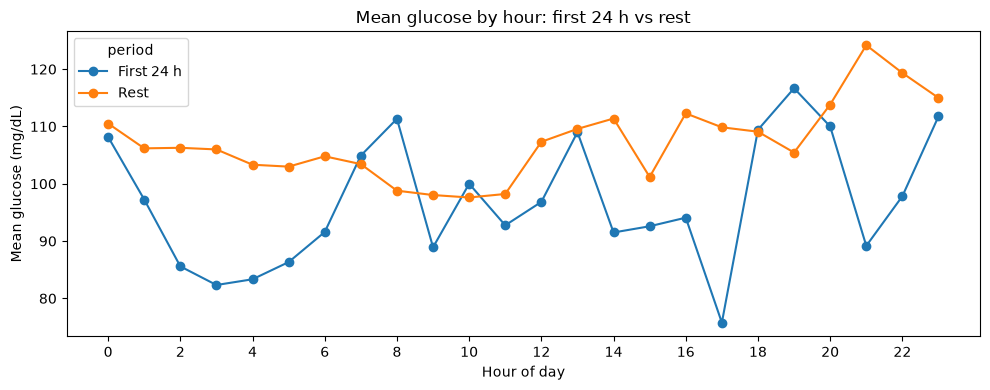

In [22]:
egv["hour"] = egv[TS_COL].dt.hour

hourly = egv.groupby(["hour", "period"])["glucose"].mean().unstack()
ax = hourly.plot(figsize=(10, 4), marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean glucose (mg/dL)")
ax.set_title("Mean glucose by hour: first 24 h vs rest")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

---
## Q6: Physically implausible jumps

Glucose normally changes slowly, usually less than 2 mg/dL per minute. Dexcom's own trend arrows treat **more than 3 mg/dL/min** as very rapid change. Jumps above about **4 mg/dL/min** are rare in people without diabetes and are worth reviewing as possible sensor noise.

We calculate the rate of change only between readings that are directly consecutive (no gap in between), because the change across a gap isn't a real rate.

In [30]:
RATE_THRESHOLD = 4  # mg/dL per minute

minutes = egv["delta"].dt.total_seconds() / 60
egv["rate"] = egv["glucose"].diff() / minutes
egv.loc[gap_mask, "rate"] = np.nan  # ignore changes across gaps

print("Rate of change (mg/dL/min):")
egv["rate"].describe().round(2)

Rate of change (mg/dL/min):


count    2558.00
mean        0.00
std         0.67
min        -4.20
25%        -0.20
50%         0.00
75%         0.20
max         3.80
Name: rate, dtype: float64

In [33]:
egv[['rate','glucose']]

,rate,glucose
0,NaN,61.0
1,-0.400000,59.0
2,-0.200000,58.0
3,0.200000,59.0
4,0.802676,63.0
...,...,...
2556,0.400000,139.0
2557,0.400000,141.0
2558,0.400000,143.0
2559,-0.802676,139.0


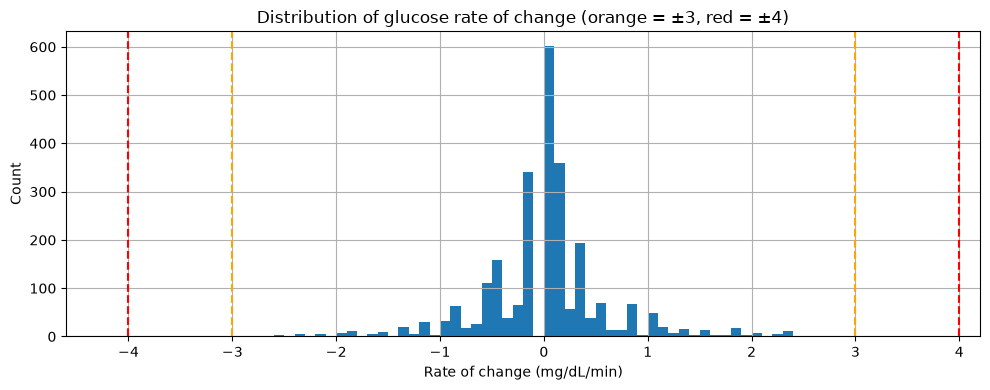

In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
egv["rate"].hist(bins=80, ax=ax)
for t in (-3, 3):
    ax.axvline(t, color="orange", ls="--")
for t in (-RATE_THRESHOLD, RATE_THRESHOLD):
    ax.axvline(t, color="red", ls="--")
ax.set_xlabel("Rate of change (mg/dL/min)")
ax.set_ylabel("Count")
ax.set_title("Distribution of glucose rate of change (orange = ±3, red = ±4)")
plt.tight_layout()
plt.show()

In [36]:
jumps = egv.loc[egv["rate"].abs() > RATE_THRESHOLD, [TS_COL, "glucose", "rate"]].copy()
jumps["previous_glucose"] = egv["glucose"].shift(1)[jumps.index]
# jumps["previous_time_stamp"] = egv[TS_COL].shift(1)[jumps.index]

print(f"Readings with |rate| > {RATE_THRESHOLD} mg/dL/min:", len(jumps))
jumps.round({"rate": 2})

Readings with |rate| > 4 mg/dL/min: 2


,Timestamp (YYYY-MM-DDThh:mm:ss),glucose,rate,previous_glucose
749,2020-02-16 07:53:30,78.0,-4.20,99.0
1319,2020-02-18 07:23:26,97.0,-4.01,117.0


### Look at each jump in context

A single spike that immediately returns to the previous level is likely **sensor noise**. A jump that continues as a sustained rise or fall is more likely **real** (for example, after a sugary meal). This cell plots one hour on each side of each flagged jump.

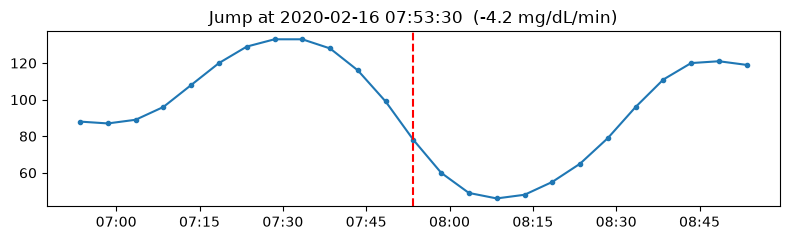

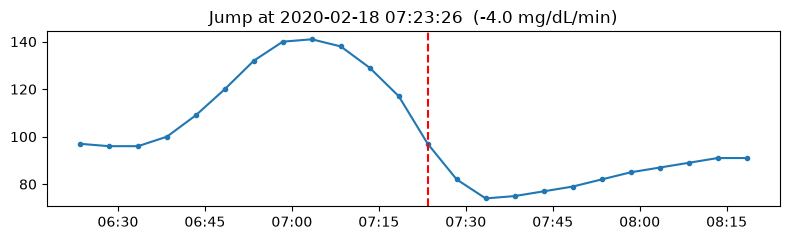

In [26]:
for _, j in jumps.head(6).iterrows():
    t = j[TS_COL]
    window = egv[(egv[TS_COL] >= t - pd.Timedelta("1h")) & (egv[TS_COL] <= t + pd.Timedelta("1h"))]

    fig, ax = plt.subplots(figsize=(8, 2.5))
    ax.plot(window[TS_COL], window["glucose"], marker="o", ms=3)
    ax.axvline(t, color="red", ls="--")
    ax.set_title(f"Jump at {t}  ({j['rate']:.1f} mg/dL/min)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

if jumps.empty:
    print("No jumps above the threshold.")

---
## Summary

All Stage 1 answers in one table. Copy these into the notes section of `questions.md`.

In [27]:
first_day = egv.loc[egv["period"] == "First 24 h", "glucose"]
rest = egv.loc[egv["period"] == "Rest", "glucose"]

summary = pd.Series({
    "Q1 First reading": str(start),
    "Q1 Last reading": str(end),
    "Q1 Days of data": round(duration / pd.Timedelta("1D"), 2),
    "Q2 Expected readings": expected,
    "Q2 Actual readings": actual,
    "Q2 Missing %": round(missing / expected * 100, 1),
    "Q3 Number of gaps": len(gaps),
    "Q3 Longest gap (min)": gaps["duration_min"].max() if len(gaps) else 0,
    "Q3 Gaps > 2 h (possible sensor change)": int((gaps["duration_min"] > 120).sum()),
    "Q4 Non-numeric values": len(non_numeric),
    "Q4 Values outside 40–400": len(out_of_range),
    "Q5 Mean first 24 h": round(first_day.mean(), 1),
    "Q5 Mean rest": round(rest.mean(), 1),
    "Q6 Jumps > 4 mg/dL/min": len(jumps),
}, name="value")

summary.to_frame()

,value
Q1 First reading,2020-02-13 17:23:32
Q1 Last reading,2020-02-22 17:53:23
Q1 Days of data,9.02
Q2 Expected readings,2598
Q2 Actual readings,2561
Q2 Missing %,1.4
Q3 Number of gaps,2
Q3 Longest gap (min),190.0
Q3 Gaps > 2 h (possible sensor change),1
Q4 Non-numeric values,0


## Save the cleaned data for the next stages

We save a clean version with just the timestamp and numeric glucose, so later notebooks can load it directly without repeating these steps.

Decide here whether to drop the first 24 hours, based on what Q5 showed. The cell keeps everything by default.

In [28]:
DROP_FIRST_24H = False

clean = egv[[TS_COL, "glucose"]].rename(columns={TS_COL: "timestamp"}).dropna()
if DROP_FIRST_24H:
    clean = clean[clean["timestamp"] >= first_24h_end]

clean.to_csv("glucose_001_clean.csv", index=False)
print("Saved", len(clean), "rows to glucose_001_clean.csv")

Saved 2561 rows to glucose_001_clean.csv
